# Análise de Fourier do Movimento de um Pêndulo Simples

## 1. Modelagem da Equação Diferencial e Dependência do Período com a Amplitude

### 1.1 A Equação Diferencial Não Linear
Considerando um pêndulo simples de massa $m$ e comprimento $L$, sujeito à aceleração da gravidade $g$, a aplicação da Segunda Lei de Newton para o movimento rotacional fornece a seguinte Equação Diferencial Ordinária (EDO) de segunda ordem:

$$\frac{d^2\theta}{dt^2} + \omega_0^2 \sin\theta = 0$$

Onde $\theta(t)$ representa o deslocamento angular em relação à posição de equilíbrio vertical e $\omega_0 = \sqrt{\frac{g}{L}}$ é a frequência natural do sistema para oscilações de pequena amplitude.

### 1.2 O Comportamento do Período em Grandes Amplitudes
Para pequenas amplitudes ($\theta_0 \le 10^\circ$), adota-se a aproximação de Taylor $\sin\theta \approx \theta$. Sob essa hipótese, a equação assume a forma do Movimento Harmônico Simples (MHS), produzindo um período constante e independente da amplitude inicial $\theta_0$:

$$T_0 = \frac{2\pi}{\omega_0} = 2\pi\sqrt{\frac{L}{g}}$$

Quando a amplitude de oscilação aumenta ($\theta_0 > 20^\circ$), o termo não linear $\sin\theta$ passa a ser relevante. A força restauradora é menor do que seria no caso linear, o que desacelera a taxa de variação angular e **aumenta o período de oscilação $T$**. O período exato passa a depender de uma integral elíptica completa de primeira espécie $K(k)$:

$$T(\theta_0) = T_0 \cdot \frac{2}{\pi} K\left(\sin\frac{\theta_0}{2}\right)$$

Aproximando essa integral via expansão em série de potências, obtemos a relação entre o período real $T$ e a amplitude inicial $\theta_0$:

$$T(\theta_0) \approx T_0 \left( 1 + \frac{1}{16}\theta_0^2 + \frac{11}{3072}\theta_0^4 + \dots \right)$$

## 2. Dedução Teórica da Frequência Angular Não Linear (Equação 7)

### 2.1 Representação em Série de Cossenos
Devido às propriedades físicas do movimento do pêndulo simples liberado a partir do repouso no instante $t=0$ com ângulo inicial $\theta_m$, a função do deslocamento angular $\theta(t)$ apresenta simetria par, ou seja, $\theta(-t) = \theta(t)$. Além disso, devido à simetria ímpar da força restauradora, o movimento contém apenas harmônicos ímpares na sua expansão em Série de Fourier de Cossenos:

$$\theta(t) = \sum_{n=1,3,5,\dots}^{\infty} a_n \cos(n \omega t)$$

Onde $\omega = \frac{2\pi}{T}$ representa a frequência angular fundamental do movimento real (que diminui conforme a amplitude cresce).

### 2.2 Dedução da Equação (7)
A frequência angular fundamental $\omega$ está ligada ao período de oscilação $T$ pela relação $\omega = \frac{2\pi}{T}$. 

Considerando a expansão em série de potências da integral elíptica que determina o período exato do pêndulo para uma amplitude máxima $\theta_m$:

$$T(\theta_m) = T_0 \left( 1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots \right)$$

Sabendo que o período para pequenas oscilações é $T_0 = \frac{2\pi}{\omega_0}$, podemos substituir $T_0$ na equação do período $T$:

$$T(\theta_m) = \frac{2\pi}{\omega_0} \left( 1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots \right)$$

Substituindo este período na definição de frequência angular $\omega = \frac{2\pi}{T(\theta_m)}$:

$$\omega = \frac{2\pi}{\frac{2\pi}{\omega_0} \left( 1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots \right)}$$

Cancelando o termo $2\pi$, obtemos a **Equação (7)** do artigo:

$$\omega = \frac{\omega_0}{1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots}$$

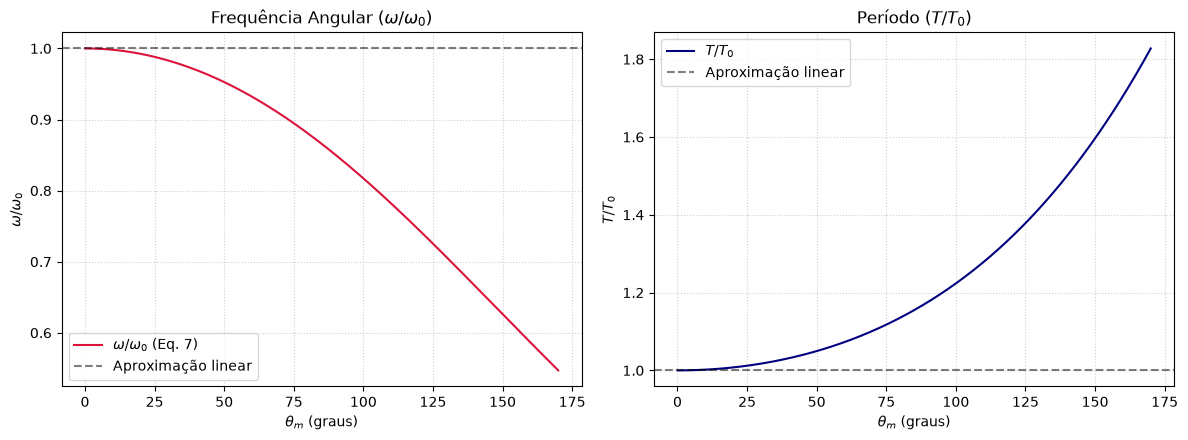

 theta_m (deg)  |  omega/omega_0  |      T/T_0     
---------------------------------------------------
      10       ° |     0.9981      |     1.0019     
      30       ° |     0.9829      |     1.0174     
      60       ° |     0.9321      |     1.0728     
      90       ° |     0.8503      |     1.1760     
      120      ° |     0.7446      |     1.3431     
      150      ° |     0.6263      |     1.5966     


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Intervalo de ângulos iniciais (0 a 170 graus)
theta_m_deg = np.linspace(0.1, 170, 500)
theta_m_rad = np.radians(theta_m_deg)

# Cálculo da frequência omega/omega_0 pela Equação (7)
omega_relativo = 1.0 / (1.0 + (1.0/16.0)*(theta_m_rad**2) + (11.0/3072.0)*(theta_m_rad**4))

# Razão dos períodos T/T_0
T_relativo = 1.0 / omega_relativo

# Plotagem dos gráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Frequência angular
ax1.plot(theta_m_deg, omega_relativo, color='crimson', label=r'$\omega / \omega_0$ (Eq. 7)')
ax1.axhline(1.0, color='black', linestyle='--', alpha=0.5, label='Aproximação linear')
ax1.set_title(r'Frequência Angular ($\omega / \omega_0$)')
ax1.set_xlabel(r'$\theta_m$ (graus)')
ax1.set_ylabel(r'$\omega / \omega_0$')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Período
ax2.plot(theta_m_deg, T_relativo, color='navy', label=r'$T / T_0$')
ax2.axhline(1.0, color='black', linestyle='--', alpha=0.5, label='Aproximação linear')
ax2.set_title(r'Período ($T / T_0$)')
ax2.set_xlabel(r'$\theta_m$ (graus)')
ax2.set_ylabel(r'$T / T_0$')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Exibição de alguns valores de referência
print(f"{'theta_m (deg)':^15} | {'omega/omega_0':^15} | {'T/T_0':^15}")
print("-" * 51)
for ang in [10, 30, 60, 90, 120, 150]:
    rad = np.radians(ang)
    w_rel = 1.0 / (1.0 + (1.0/16.0)*(rad**2) + (11.0/3072.0)*(rad**4))
    t_rel = 1.0 / w_rel
    print(f"{ang:^15}° | {w_rel:^15.4f} | {t_rel:^15.4f}")

## 3. Resolução Numérica da Equação do Pêndulo (Método RK4)

### 3.1 Transformação do Sistema de EDOs
A equação diferencial de segunda ordem do pêndulo não linear:

$$\frac{d^2\theta}{dt^2} + \omega_0^2 \sin\theta = 0$$

pode ser convertida em um sistema de duas Equações Diferenciais Ordinárias de primeira ordem definindo a velocidade angular $\omega = \frac{d\theta}{dt}$:

$$\begin{cases} 
\frac{d\theta}{dt} = \omega \\ 
\frac{d\omega}{dt} = -\omega_0^2 \sin\theta 
\end{cases}$$

### 3.2 Algoritmo de Runge-Kutta de 4ª Ordem (RK4)
Para resolver numericamente esse sistema, aplica-se o método RK4 iterativamente a cada passo de tempo $\Delta t$, garantindo alta precisão e estabilidade na integração do movimento angular $\theta(t)$ e da velocidade angular $\omega(t)$.

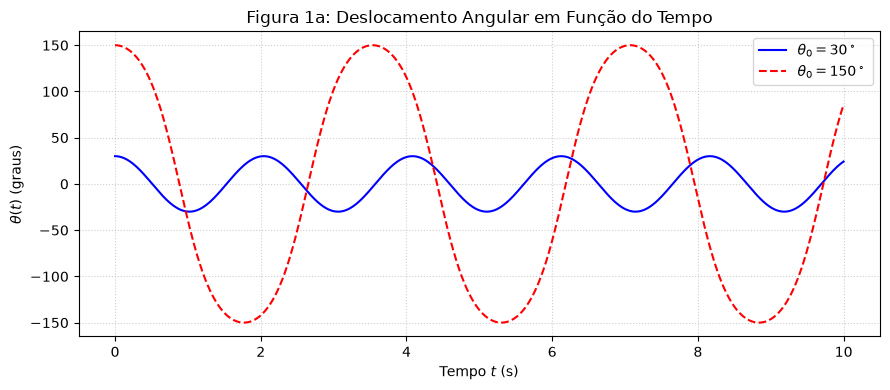

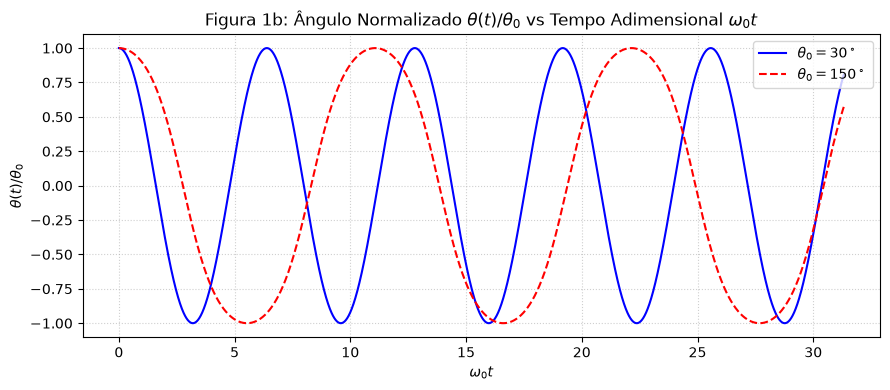

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Sistema de derivadas
def pendulo_derivatives(theta, omega, omega0):
    dtheta_dt = omega
    domega_dt = -(omega0**2) * np.sin(theta)
    return dtheta_dt, domega_dt

# Algoritmo de Runge-Kutta de 4ª Ordem
def rk4_pendulo(theta0, omega0, t_max, dt):
    t = np.arange(0, t_max, dt)
    N = len(t)
    
    theta = np.zeros(N)
    omega = np.zeros(N)
    
    # Condição inicial: solto do repouso
    theta[0] = theta0
    omega[0] = 0.0
    
    for i in range(N - 1):
        k1_th, k1_om = pendulo_derivatives(theta[i], omega[i], omega0)
        
        k2_th, k2_om = pendulo_derivatives(
            theta[i] + 0.5 * dt * k1_th, 
            omega[i] + 0.5 * dt * k1_om, 
            omega0
        )
        
        k3_th, k3_om = pendulo_derivatives(
            theta[i] + 0.5 * dt * k2_th, 
            omega[i] + 0.5 * dt * k2_om, 
            omega0
        )
        
        k4_th, k4_om = pendulo_derivatives(
            theta[i] + dt * k3_th, 
            omega[i] + dt * k3_om, 
            omega0
        )
        
        theta[i+1] = theta[i] + (dt / 6.0) * (k1_th + 2*k2_th + 2*k3_th + k4_th)
        omega[i+1] = omega[i] + (dt / 6.0) * (k1_om + 2*k2_om + 2*k3_om + k4_om)
        
    return t, theta, omega

# Parâmetros de simulação
g = 9.81
L = 1.0
omega0 = np.sqrt(g / L)
dt = 0.001
t_max = 10.0

# Ângulos de simulação (ex: 30° e 150°)
theta0_1 = np.radians(30)
theta0_2 = np.radians(150)

# Execução numérica
t1, th1, _ = rk4_pendulo(theta0_1, omega0, t_max, dt)
t2, th2, _ = rk4_pendulo(theta0_2, omega0, t_max, dt)

# Figura 1a: Movimento theta(t)
plt.figure(figsize=(9, 4))
plt.plot(t1, np.degrees(th1), label=r'$\theta_0 = 30^\circ$', color='blue')
plt.plot(t2, np.degrees(th2), label=r'$\theta_0 = 150^\circ$', color='red', linestyle='--')
plt.title('Figura 1a: Deslocamento Angular em Função do Tempo')
plt.xlabel('Tempo $t$ (s)')
plt.ylabel(r'$\theta(t)$ (graus)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Figura 1b: Resposta normalizada
plt.figure(figsize=(9, 4))
plt.plot(t1 * omega0, th1 / theta0_1, label=r'$\theta_0 = 30^\circ$', color='blue')
plt.plot(t2 * omega0, th2 / theta0_2, label=r'$\theta_0 = 150^\circ$', color='red', linestyle='--')
plt.title(r'Figura 1b: Ângulo Normalizado $\theta(t)/\theta_0$ vs Tempo Adimensional $\omega_0 t$')
plt.xlabel(r'$\omega_0 t$')
plt.ylabel(r'$\theta(t) / \theta_0$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Análise de Fourier e Decomposição em Harmônicos

### 4.1 Transformada Rápida de Fourier (FFT)
Para analisar o conteúdo de frequências do sinal angular $\theta(t)$, aplica-se a Transformada Rápida de Fourier para sinais reais (`numpy.fft.rfft`). A expansão em série de cossenos expressa a posição angular como:

$$\theta(t) = \sum_{n=1,3,5,\dots}^{\infty} a_n \cos(n \omega t)$$

Os coeficientes $a_n$ indicam a contribuição de cada harmônico $n$ na composição da onda. Em pequenas amplitudes ($\theta_0 \le 30^\circ$), o sinal é essencialmente senoidal e dominado pelo primeiro harmônico ($a_1$). Em grandes amplitudes ($\theta_0 = 150^\circ$), a deformação do sinal em relação a um cosseno puro gera harmônicos ímpares superiores ($a_3, a_5, a_7, \dots$) com amplitudes significativas.

## 5. Generalização e Adimensionação (Equação 11)

A **Equação (11)** do artigo estabelece a adimensionação do problema ao definir uma escala de tempo adimensional $\tau = \omega t$. Ao expressar os coeficientes $a_n$ em função da amplitude inicial $\theta_0$ normalizada, o comportamento espectral torna-se **universal**: ele depende exclusivamente do ângulo inicial $\theta_0$, sendo independente do comprimento $L$ do pêndulo ou da aceleração da gravidade $g$.

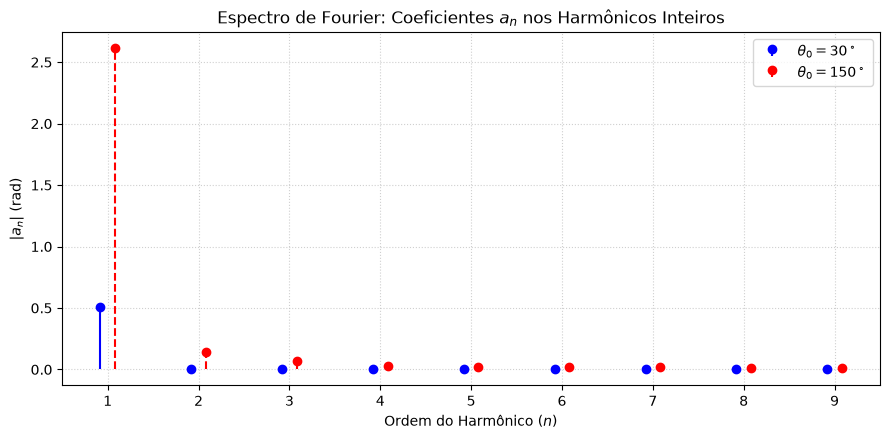

 Harmônico (n)  |    a_n (30°)    |   a_n (150°)   
---------------------------------------------------
       1        |     0.51152     |     2.61201    
       3        |     0.00276     |     0.06470    
       5        |     0.00154     |     0.02391    
       7        |     0.00101     |     0.01687    
       9        |     0.00076     |     0.01330    


In [4]:
def calcular_coeficientes_an(t, theta):
    N = len(theta)
    dt = t[1] - t[0]
    
    # FFT Real
    fft_vals = np.fft.rfft(theta)
    freqs = np.fft.rfftfreq(N, d=dt)
    
    # Coeficientes a_n da série
    a_n = (2.0 / N) * np.abs(fft_vals)
    a_n[0] = a_n[0] / 2.0
    
    # Frequência fundamental
    idx_pico = np.argmax(a_n[1:]) + 1
    f1 = freqs[idx_pico]
    
    return freqs, a_n, f1

# Cálculo dos coeficientes
freqs_30, an_30, f1_30 = calcular_coeficientes_an(t1, th1)
freqs_150, an_150, f1_150 = calcular_coeficientes_an(t2, th2)

# Filtragem dos picos nos harmônicos inteiros (n = 1, 2, 3, ..., 9)
harmonics = np.arange(1, 10)
an_30_filtered = []
an_150_filtered = []

for n in harmonics:
    idx_30 = np.argmin(np.abs(freqs_30 - n * f1_30))
    idx_150 = np.argmin(np.abs(freqs_150 - n * f1_150))
    an_30_filtered.append(an_30[idx_30])
    an_150_filtered.append(an_150[idx_150])

# Plotagem limpa dos harmônicos
plt.figure(figsize=(9, 4.5))
plt.stem(harmonics - 0.08, an_30_filtered, linefmt='b-', markerfmt='bo', basefmt=' ', label=r'$\theta_0 = 30^\circ$')
plt.stem(harmonics + 0.08, an_150_filtered, linefmt='r--', markerfmt='ro', basefmt=' ', label=r'$\theta_0 = 150^\circ$')

plt.xlim(0.5, 9.5)
plt.xticks(harmonics)
plt.title(r'Espectro de Fourier: Coeficientes $a_n$ nos Harmônicos Inteiros')
plt.xlabel('Ordem do Harmônico ($n$)')
plt.ylabel(r'$|a_n|$ (rad)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Exibição dos harmônicos ímpares
print(f"{'Harmônico (n)':^15} | {'a_n (30°)':^15} | {'a_n (150°)':^15}")
print("-" * 51)
for i, n in enumerate(harmonics):
    if n % 2 != 0:  # Apenas ímpares
        print(f"{n:^15} | {an_30_filtered[i]:^15.5f} | {an_150_filtered[i]:^15.5f}")